In [3]:
import numpy as np
import pandas as pd

In [4]:
df=pd.read_csv("modified_placement_data.csv")

In [5]:
df.head()

,cgpa,iq,placement
0,"6,8",123.0,Yes
1,"5,9",106.0,No
2,"5,3",121.0,No
3,"7,4",132.0,Yes
4,"5,8",142.0,No


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       95 non-null     str    
 1   iq         100 non-null    float64
 2   placement  100 non-null    str    
dtypes: float64(1), str(2)
memory usage: 2.5 KB


In [7]:
## df = df.iloc[:,1:] it is used to remove the first column of the dataframe,which is often an index column that is not needed for analysis. By using iloc[:,1:], we are selecting all rows (:) and all columns starting from the second column (1:), effectively dropping the first column. This can be useful when the first column does not contain relevant information for the analysis or modeling tasks.

In [8]:
df.head()

,cgpa,iq,placement
0,"6,8",123.0,Yes
1,"5,9",106.0,No
2,"5,3",121.0,No
3,"7,4",132.0,Yes
4,"5,8",142.0,No


In [9]:
import pandas as pd

# Convert values such as "6,8" to 6.8 and make the column numeric
df["cgpa"] = pd.to_numeric(
    df["cgpa"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

In [10]:
# Fill missing CGPA values with the median
median_cgpa = df["cgpa"].median()
df["cgpa"] = df["cgpa"].fillna(median_cgpa)

# Check the result
print("Median used:", median_cgpa)
print("Missing CGPA values remaining:", df["cgpa"].isna().sum())
print(df["cgpa"].head())

Median used: 6.0
Missing CGPA values remaining: 0
0    6.8
1    5.9
2    5.3
3    7.4
4    5.8
Name: cgpa, dtype: Float64


In [11]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,Yes
1,5.9,106.0,No
2,5.3,121.0,No
3,7.4,132.0,Yes
4,5.8,142.0,No


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    Float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    str    
dtypes: Float64(1), float64(1), str(1)
memory usage: 2.6 KB


In [13]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model

In [15]:
import matplotlib.pyplot as plt

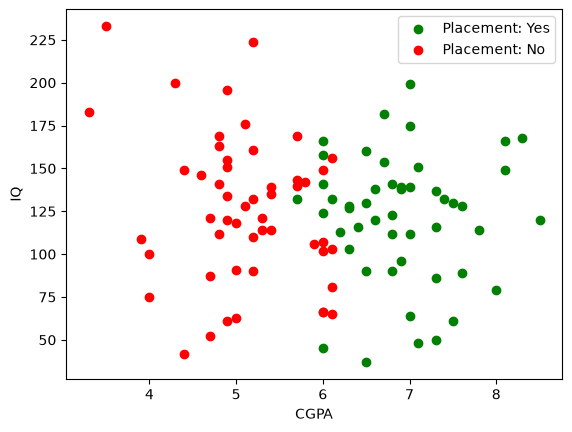

In [20]:

plt.scatter(
    df["cgpa"][df["placement"] == "Yes"],
    df["iq"][df["placement"] == "Yes"],
    color="green",
    label="Placement: Yes"
)

plt.scatter(
    df["cgpa"][df["placement"] == "No"],
    df["iq"][df["placement"] == "No"],
    color="red",
    label="Placement: No"
)

plt.xlabel("CGPA")
plt.ylabel("IQ")
plt.legend()
plt.show()

In [21]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,Yes
1,5.9,106.0,No
2,5.3,121.0,No
3,7.4,132.0,Yes
4,5.8,142.0,No


In [22]:
df["placement"] = df["placement"].map({"Yes": 1, "No": 0})

In [23]:
print(df["placement"].value_counts())
print(df["placement"].head())

placement
1    50
0    50
Name: count, dtype: int64
0    1
1    0
2    0
3    1
4    0
Name: placement, dtype: int64


In [25]:
X = df.iloc[:,0:2]
Y=df.iloc[:,-1]

In [26]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [27]:
Y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [28]:
df.shape

(100, 3)

In [ ]:
X.shape ## This is a 2D tensor or a matrix

(100, 2)

In [31]:
Y.shape ## This is a 1D tensor or a vector.

(100,)

In [33]:
from sklearn.model_selection import train_test_split

In [36]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.1,random_state=42)

In [37]:
X_train

,cgpa,iq
18,4.0,100.0
30,7.6,128.0
73,4.9,61.0
33,6.0,149.0
90,7.3,86.0
...,...,...
60,6.9,139.0
71,6.1,132.0
14,6.1,103.0
92,5.2,110.0


In [38]:
X_test

,cgpa,iq
83,7.5,130.0
53,8.3,168.0
70,6.3,127.0
45,6.0,66.0
44,7.5,61.0
39,4.6,146.0
22,4.9,120.0
80,4.9,196.0
10,6.0,45.0
0,6.8,123.0


In [39]:
Y_train

18    0
30    1
73    0
33    0
90    1
     ..
60    1
71    1
14    0
92    0
51    0
Name: placement, Length: 90, dtype: int64

In [40]:
Y_test

83    1
53    1
70    1
45    1
44    1
39    0
22    0
80    0
10    1
0     1
Name: placement, dtype: int64

In [41]:
from sklearn.preprocessing import StandardScaler


In [42]:
scaler = StandardScaler()


In [46]:
X_train_scaled=scaler.fit_transform(X_train)

In [47]:
X_train_scaled

array([[-1.76346263, -0.62029848],
       [ 1.48106827,  0.09806189],
       [-0.9523299 , -1.62087186],
       [ 0.03905454,  0.63683217],
       [ 1.2106907 , -0.97947867],
       [-0.14119718,  0.45724208],
       [-0.9523299 ,  0.79076654],
       [ 1.2106907 , -1.90308486],
       [-0.50170061,  0.3802749 ],
       [-1.85358849, -0.38939693],
       [ 1.66131999, -0.26111829],
       [-1.4029592 ,  0.63683217],
       [ 0.94031312,  1.91961855],
       [ 1.48106827, -0.90251149],
       [ 2.292201  , -0.10718393],
       [-0.77207819,  1.32953682],
       [-0.9523299 ,  0.25199626],
       [-1.4029592 , -2.10833068],
       [ 0.03905454, -1.49259322],
       [ 1.2106907 , -0.20980684],
       [ 0.85018727,  0.35461917],
       [-0.68195233,  0.9447009 ],
       [ 0.03905454,  1.07297954],
       [-0.68195233, -0.87685576],
       [ 0.76006141, -0.31242975],
       [ 1.03043898, -1.95439632],
       [ 0.85018727, -0.72292139],
       [ 1.93169757,  1.07297954],
       [ 0.76006141,

In [49]:
X_test_scaled=scaler.fit_transform(X_test)

In [51]:
X_test_scaled

array([[ 1.0268429 ,  0.25809017],
       [ 1.70018251,  1.08922801],
       [ 0.01683349,  0.19247403],
       [-0.23566886, -1.14172092],
       [ 1.0268429 , -1.25108116],
       [-1.41401318,  0.60804294],
       [-1.16151082,  0.03936969],
       [-1.16151082,  1.70164536],
       [-0.23566886, -1.60103394],
       [ 0.43767075,  0.10498583]])

In [52]:
from sklearn.linear_model import LogisticRegression

In [53]:
LR=LogisticRegression()

In [54]:
LR.fit(X_train,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [59]:
y_pred=LR.predict(X_test)

In [57]:
Y_test

83    1
53    1
70    1
45    1
44    1
39    0
22    0
80    0
10    1
0     1
Name: placement, dtype: int64

In [60]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [62]:
accuracy_value=accuracy_score(y_pred,Y_test)
print("Accuracy value is :",accuracy_value)

Accuracy value is : 0.8


<Axes: >

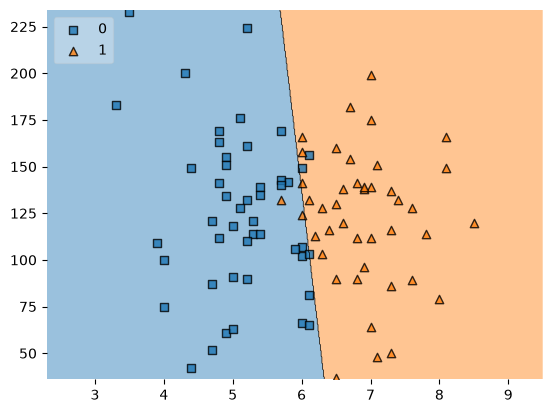

In [68]:
import pandas as pd
from mlxtend.plotting import plot_decision_regions

# Convert feature values to numbers (also handles decimal commas like "6,8")
X_plot = X_train.apply(
    lambda column: pd.to_numeric(
        column.astype(str).str.replace(",", ".", regex=False)
    )
).to_numpy(dtype=float)

# Convert the target labels to integers
y_plot = (
    pd.Series(Y_train)
    .replace({"No": 0, "Yes": 1})
    .to_numpy(dtype=int)
)

# Fit the model using these numeric values
LR.fit(X_plot, y_plot)

# Plot the decision regions
plot_decision_regions(X_plot, y_plot, clf=LR, legend=2)

In [69]:
import pickle

In [70]:
pickle.dump(LR,open("placement_model.pkl","wb"))